# CYP2D6 dataset composition — S1 Fig

Builds a five-panel supplementary figure describing the composition of the full
CYP2D6 diplotype–drug dataset (`dataset.csv`), plus the per-allele and
per-diplotype count tables.

- **A** star-allele counts, coloured by functional status
- **B** cumulative coverage curves for alleles and diplotypes
- **C** the 20 most frequent diplotypes
- **D** activity score × phenotype
- **E** the 15 most frequent substrate drugs

Run the cells in order. Only the path in the **Configuration** cell needs changing.

## Setup

In [1]:
import re
from collections import Counter
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.gridspec import GridSpec
from matplotlib.patches import Patch

%matplotlib inline

In [26]:
# ---- Configuration -------------------------------------------------------
INPUT  = Path("dataset.csv")   # <-- path to the full dataset
OUTDIR = Path(".")              # <-- where figures and tables are written
SAVE   = True                   # set False to preview without writing files

OUTDIR.mkdir(parents=True, exist_ok=True)
print("input exists:", INPUT.exists())

input exists: True


In [27]:
# ---- Plot style: PLOS-oriented -------------------------------------------
# Liberation Sans is metrically identical to Arial; it is used automatically
# when Arial is unavailable.
mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Liberation Sans", "Helvetica", "DejaVu Sans"],
    "font.size": 7,
    "axes.labelsize": 7.5,
    "axes.titlesize": 8,
    "xtick.labelsize": 6.5,
    "ytick.labelsize": 6.5,
    "legend.fontsize": 6.5,
    "axes.linewidth": 0.6,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
    "xtick.major.size": 2.5,
    "ytick.major.size": 2.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 110,
    "savefig.bbox": "tight",
    "pdf.fonttype": 42,   # embed TrueType, required by most journals
    "ps.fonttype": 42,
})

In [28]:
# ---- Palette -------------------------------------------------------------
# Single-hue sequential ramp encoding CYP2D6 activity (more activity -> darker);
# monotonic in lightness, so it survives greyscale printing and colour-vision
# deficiency.
C_NORMAL    = "#08519C"   # activity value 1.0
C_DECREASED = "#4292C6"   # 0 < activity value < 1
C_NONE      = "#9ECAE1"   # activity value 0
C_UNKNOWN   = "#D9D9D9"   # no activity value assignable

# Categorical pair for the two cumulative curves (Okabe-Ito; CVD dE 21.9)
C_ALLELE = "#0072B2"
C_DIPLO  = "#D55E00"

INK, INK_MUTED, GRID = "#1A1A1A", "#6B6B6B", "#E6E6E6"

FUNC_ORDER = ["Normal function", "Decreased function", "No function",
              "Uncertain / not assigned"]
FUNC_COLOR = dict(zip(FUNC_ORDER, [C_NORMAL, C_DECREASED, C_NONE, C_UNKNOWN]))

PHENO_SHORT = {
    "CYP2D6 Normal Metabolizer": "NM",
    "CYP2D6 Intermediate Metabolizer": "IM",
    "CYP2D6 Poor Metabolizer": "PM",
    "CYP2D6 Ultrarapid Metabolizer": "UM",
    "CYP2D6 Indeterminate": "Indeterminate",
}
PHENO_ORDER = ["NM", "IM", "PM", "UM", "Indeterminate", "Not reported"]
PHENO_COLOR = {"NM": C_NORMAL, "IM": C_DECREASED, "PM": C_NONE,
               "UM": "#08306B", "Indeterminate": "#BDBDBD",
               "Not reported": "#E8E8E8"}

# Display aliases for drug names too long for an axis tick
DRUG_ALIAS = {"3,4-methylenedioxymethamphetamine": "MDMA"}

## Load and parse

In [29]:
def star(allele):
    """'CYP2D6.4.001' -> '*4'. Passes through anything already star-formatted."""
    a = str(allele).strip()
    m = re.match(r"CYP2D6\.([0-9A-Za-z]+)\.?\d*", a)
    if m:
        return "*" + m.group(1)
    return a if a.startswith("*") else "*" + a


def star_key(s):
    """Numeric sort key so *10 follows *9 rather than *1."""
    digits = re.sub(r"\D", "", s)
    return (int(digits) if digits else 10**6, s)


def diplotype_label(alleles):
    return "/".join(sorted(alleles, key=star_key))


def load(path):
    df = pd.read_csv(path)
    df.columns = [c.strip() for c in df.columns]
    df = df.loc[:, ~df.columns.str.startswith("Unnamed")]
    df = df[df["Variant"].notna()].copy()
    df["alleles"] = df["Variant"].apply(
        lambda v: [star(x) for x in str(v).split(";") if x.strip()])
    df["diplotype"] = df["alleles"].apply(diplotype_label)
    df["pheno"] = df["phenotype"].map(PHENO_SHORT).fillna("Indeterminate")
    return df


df = load(INPUT)
print(df.shape)
df[["Variant", "diplotype", "Drug", "Class", "activity_score", "pheno"]].head()

(622, 12)


,Variant,diplotype,Drug,Class,activity_score,pheno
0,CYP2D6.5.001; CYP2D6.41.001,*5/*41,"3,4-methylenedioxymethamphetamine",de,0.25,IM
1,CYP2D6.4.001; CYP2D6.9.001,*4/*9,"3,4-methylenedioxymethamphetamine",de,0.25,IM
2,CYP2D6.10.001; CYP2D6.10.001,*10/*10,"3,4-methylenedioxymethamphetamine",de,0.50,IM
3,CYP2D6.5.001; CYP2D6.10.001,*5/*10,"3,4-methylenedioxymethamphetamine",de,0.25,IM
4,CYP2D6.10.001; CYP2D6.41.001,*10/*41,"3,4-methylenedioxymethamphetamine",de,0.50,IM


## Allele activity values, solved from the data

Rather than hard-coding an external CPIC table, each allele's activity value is
recovered from the dataset itself by least-squares decomposition of the
diplotype activity scores, using the additive relation

$$\mathrm{AS} = v(\text{allele}_1) + v(\text{allele}_2)$$

This keeps the functional annotation in panel A internally consistent with the
activity scores used as model targets, and the residual below makes the
assumption auditable.

In [30]:
def solve_activity_values(df):
    rows = [(a, float(s)) for a, s in zip(df["alleles"], df["activity_score"])
            if len(a) == 2 and pd.notna(s)]
    alleles = sorted({a for pair, _ in rows for a in pair}, key=star_key)
    idx = {a: i for i, a in enumerate(alleles)}

    X = np.zeros((len(rows), len(alleles)))
    y = np.zeros(len(rows))
    for r, (pair, s) in enumerate(rows):
        for a in pair:
            X[r, idx[a]] += 1.0
        y[r] = s

    sol, *_ = np.linalg.lstsq(X, y, rcond=None)
    resid = np.abs(X @ sol - y)

    # Keep only values that land cleanly on the 0.25 grid CPIC uses; anything
    # else is an under-determined column and is left unassigned.
    values = {a: round(sol[i] * 4) / 4 for a, i in idx.items()
              if abs(sol[i] - round(sol[i] * 4) / 4) < 0.08}
    return values, float(resid.mean()), float(resid.max())


def classify(value):
    if value is None:
        return "Uncertain / not assigned"
    if value >= 1.0:
        return "Normal function"
    if value > 0:
        return "Decreased function"
    return "No function"


av, resid_mean, resid_max = solve_activity_values(df)
print(f"mean |residual| = {resid_mean:.4f}   max = {resid_max:.3f}")
print(f"values assigned for {len(av)} alleles")
pd.Series(av).sort_index(key=lambda s: [star_key(x) for x in s]).to_frame("activity value").T

mean |residual| = 0.0107   max = 0.430
values assigned for 37 alleles


,*1,*2,*3,*4,*5,*6,*7,*8,*9,*10,...,*44,*49,*52,*56,*59,*62,*69,*81,*100,*101
activity value,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.25,0.25,...,0.0,0.5,0.25,0.0,0.5,0.0,0.0,0.0,0.0,0.0


In [31]:
allele_counts = Counter(a for xs in df["alleles"] for a in xs)
diplo_counts  = Counter(df["diplotype"])
func_of       = {a: classify(av.get(a)) for a in allele_counts}

total_alleles = sum(allele_counts.values())
ranked = [c for _, c in allele_counts.most_common()]
dranked = [c for _, c in diplo_counts.most_common()]

print(f"records            : {len(df)}")
print(f"distinct alleles   : {len(allele_counts)}  ({total_alleles} observations)")
print(f"distinct diplotypes: {len(diplo_counts)}")
print(f"distinct drugs     : {df['Drug'].nunique()}   publications: {df['Literature'].nunique()}")
for k in (3, 5, 10):
    print(f"top {k:>2} alleles    : {sum(ranked[:k]) / total_alleles:6.1%} of allele observations")
for k in (10, 20):
    print(f"top {k:>2} diplotypes : {sum(dranked[:k]) / len(df):6.1%} of records")
print(f"diplotypes seen once: {sum(1 for v in diplo_counts.values() if v == 1)}")
print(f"diplotypes seen <=2x: {sum(1 for v in diplo_counts.values() if v <= 2)}")

records            : 622
distinct alleles   : 41  (1244 observations)
distinct diplotypes: 104
distinct drugs     : 59   publications: 171
top  3 alleles    :  54.7% of allele observations
top  5 alleles    :  72.7% of allele observations
top 10 alleles    :  93.3% of allele observations
top 10 diplotypes :  50.3% of records
top 20 diplotypes :  71.5% of records
diplotypes seen once: 53
diplotypes seen <=2x: 69


## Panels

In [32]:
def panel_alleles(ax, allele_counts, func_of, n_records):
    order  = [a for a, _ in allele_counts.most_common()]
    vals   = [allele_counts[a] for a in order]
    ypos   = np.arange(len(order))[::-1]
    colors = [FUNC_COLOR[func_of[a]] for a in order]

    ax.barh(ypos, vals, height=0.74, color=colors,
            edgecolor="white", linewidth=0.35, zorder=3)
    ax.set_yticks(ypos)
    ax.set_yticklabels(order, fontsize=5.8)
    ax.tick_params(axis="y", length=0, pad=1.5)

    total, xmax = sum(vals), max(vals)
    for yp, v in zip(ypos, vals):
        ax.text(v + xmax * 0.012, yp, f"{v}  ({v / total * 100:.1f}%)",
                va="center", ha="left", fontsize=5.3, color=INK_MUTED, zorder=4)

    ax.set_xlim(0, xmax * 1.30)
    ax.set_ylim(-0.9, len(order) - 0.1)
    ax.set_xlabel(f"Allele count (of {total} allele observations)")
    ax.xaxis.grid(True, color=GRID, linewidth=0.5, zorder=0)
    ax.set_axisbelow(True)
    ax.spines["left"].set_visible(False)

    present = [f for f in FUNC_ORDER if f in set(func_of.values())]
    ax.legend(handles=[Patch(facecolor=FUNC_COLOR[f], edgecolor="white",
                             linewidth=0.35, label=f) for f in present],
              loc="lower right", frameon=False, handlelength=1.1,
              handleheight=0.9, borderpad=0.2, labelspacing=0.35)
    ax.set_title(f"Star-allele counts ({len(order)} distinct alleles, "
                 f"{n_records} records)", loc="left", pad=5)

In [33]:
def panel_cumulative(ax, allele_counts, diplo_counts):
    for counts, color, label in ((allele_counts, C_ALLELE, "Alleles"),
                                 (diplo_counts,  C_DIPLO,  "Diplotypes")):
        v   = np.array([c for _, c in counts.most_common()], dtype=float)
        cum = np.concatenate([[0], np.cumsum(v) / v.sum() * 100])
        x   = np.arange(len(cum)) / (len(cum) - 1) * 100
        ax.plot(x, cum, color=color, linewidth=1.8, label=label,
                solid_capstyle="round", zorder=3)

    ax.plot([0, 100], [0, 100], color=INK_MUTED, linewidth=0.8,
            linestyle=(0, (3, 2)), zorder=2)
    ax.text(62, 56, "uniform", fontsize=5.8, color=INK_MUTED,
            rotation=38, rotation_mode="anchor")

    ax.set_xlim(0, 100)
    ax.set_ylim(0, 101)
    ax.set_xlabel("Distinct types, ranked by count (%)")
    ax.set_ylabel("Cumulative share of\nobservations (%)")
    ax.yaxis.grid(True, color=GRID, linewidth=0.5, zorder=0)
    ax.set_axisbelow(True)
    ax.legend(loc="lower right", frameon=False, handlelength=1.4, borderpad=0.2)
    ax.set_title("Concentration of the dataset", loc="left", pad=5)

In [34]:
def panel_top_diplotypes(ax, diplo_counts, top_n=20):
    items = diplo_counts.most_common(top_n)
    names = [k for k, _ in items]
    vals  = [v for _, v in items]
    total = sum(diplo_counts.values())
    x     = np.arange(len(names))

    ax.bar(x, vals, width=0.72, color=C_DECREASED, edgecolor="white",
           linewidth=0.35, zorder=3)
    for xi, v in zip(x, vals):
        ax.text(xi, v + max(vals) * 0.02, str(v), ha="center", va="bottom",
                fontsize=5.4, color=INK_MUTED, zorder=4)

    ax.set_xticks(x)
    ax.set_xticklabels(names, rotation=55, ha="right", fontsize=5.8)
    ax.tick_params(axis="x", length=0, pad=1)
    ax.set_ylim(0, max(vals) * 1.16)
    ax.set_xlim(-0.8, len(names) - 0.2)
    ax.set_ylabel("Records")
    ax.yaxis.grid(True, color=GRID, linewidth=0.5, zorder=0)
    ax.set_axisbelow(True)

    shown = sum(vals)
    ax.set_title(f"{top_n} most frequent diplotypes "
                 f"({shown}/{total} records, {shown / total * 100:.0f}%)",
                 loc="left", pad=5)

In [35]:
def panel_activity(ax, df):
    scores = sorted(df["activity_score"].dropna().unique())
    masks  = [df["activity_score"] == s for s in scores]
    labels = [f"{s:g}" for s in scores]

    n_na = int(df["activity_score"].isna().sum())
    if n_na:
        masks.append(df["activity_score"].isna())
        labels.append("n/a")

    pheno  = df["pheno"].replace({"Not reported": "Indeterminate"})
    phenos = [p for p in PHENO_ORDER if p in set(pheno)]
    bottom = np.zeros(len(labels))
    x      = np.arange(len(labels))

    for p in phenos:
        vals = np.array([int((m & (pheno == p)).sum()) for m in masks],
                        dtype=float)
        if vals.sum() == 0:
            continue
        ax.bar(x, vals, bottom=bottom, width=0.70, color=PHENO_COLOR[p],
               edgecolor="white", linewidth=0.7, label=p, zorder=3)
        bottom += vals

    for xi, tot in zip(x, bottom):
        ax.text(xi, tot + bottom.max() * 0.025, f"{int(tot)}", ha="center",
                va="bottom", fontsize=5.8, color=INK_MUTED, zorder=4)

    if n_na:
        ax.axvline(len(scores) - 0.5, color=INK_MUTED, linewidth=0.6,
                   linestyle=(0, (2, 2)), alpha=0.5, zorder=1)
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.set_xlabel("CYP2D6 activity score")
    ax.set_ylabel("Records")
    ax.set_ylim(0, bottom.max() * 1.32)
    ax.yaxis.grid(True, color=GRID, linewidth=0.5, zorder=0)
    ax.set_axisbelow(True)
    ax.legend(loc="upper center", bbox_to_anchor=(0.52, 1.0), ncol=2,
              frameon=False, handlelength=1.0, handleheight=0.9,
              borderpad=0.1, labelspacing=0.28, columnspacing=0.9,
              fontsize=5.8, title="Phenotype", title_fontsize=6.2)
    n_scored = int(df["activity_score"].notna().sum())
    ax.set_title(f"Activity score and phenotype (n = {len(df)})",
                 loc="left", pad=5)

In [36]:
def panel_drugs(ax, df, top_n=15):
    vc    = df["Drug"].value_counts()
    items = vc.head(top_n)[::-1]
    y     = np.arange(len(items))

    ax.barh(y, items.values, height=0.70, color=C_ALLELE,
            edgecolor="white", linewidth=0.35, zorder=3)
    labels = [DRUG_ALIAS.get(d, d if len(d) <= 22 else d[:20] + "…")
              for d in items.index]
    ax.set_yticks(y)
    ax.set_yticklabels(labels, fontsize=5.8)
    ax.tick_params(axis="y", length=0, pad=1.5)
    for yi, v in zip(y, items.values):
        ax.text(v + items.values.max() * 0.015, yi, str(v), va="center",
                ha="left", fontsize=5.4, color=INK_MUTED, zorder=4)

    ax.set_xlim(0, items.values.max() * 1.15)
    ax.set_xlabel("Records")
    ax.xaxis.grid(True, color=GRID, linewidth=0.5, zorder=0)
    ax.set_axisbelow(True)
    ax.spines["left"].set_visible(False)
    ax.set_title(f"{top_n} most frequent drugs of {vc.size} "
                 f"({items.values.sum()}/{len(df)} records)", loc="left", pad=5)

## Assemble the figure

written:
  S1_Fig_dataset_composition.png
  S1_Fig_dataset_composition.pdf
  S1_Fig_dataset_composition.tiff


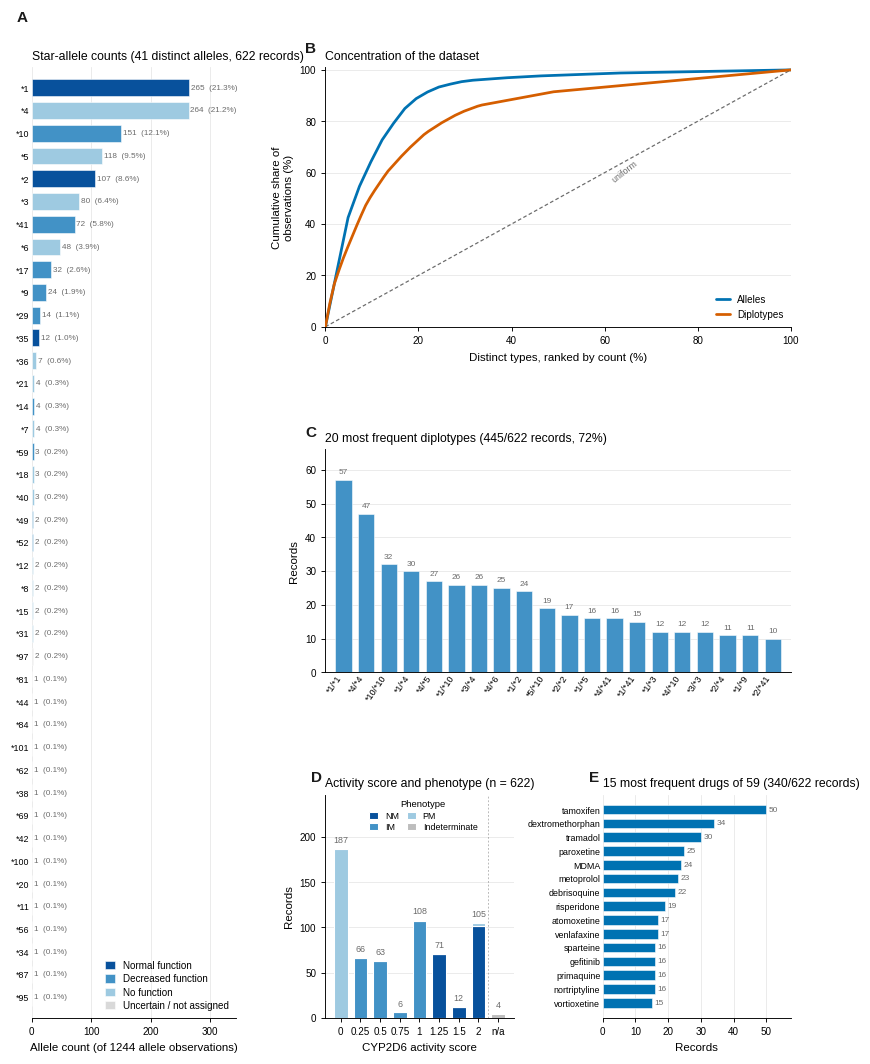

In [37]:
fig = plt.figure(figsize=(7.5, 9.6))
gs  = GridSpec(3, 3, figure=fig,
               width_ratios=[1.00, 0.92, 0.92],
               height_ratios=[1.00, 0.86, 0.86],
               wspace=0.46, hspace=0.52,
               left=0.065, right=0.985, top=0.955, bottom=0.055)

ax_a = fig.add_subplot(gs[:, 0])
ax_b = fig.add_subplot(gs[0, 1:])
ax_c = fig.add_subplot(gs[1, 1:])
ax_d = fig.add_subplot(gs[2, 1])
ax_e = fig.add_subplot(gs[2, 2])

panel_alleles(ax_a, allele_counts, func_of, len(df))
panel_cumulative(ax_b, allele_counts, diplo_counts)
panel_top_diplotypes(ax_c, diplo_counts)
panel_activity(ax_d, df)
panel_drugs(ax_e, df)

for ax, letter in ((ax_a, "A"), (ax_b, "B"), (ax_c, "C"), (ax_d, "D"), (ax_e, "E")):
    ax.text(-0.02, 1.045, letter, transform=ax.transAxes, fontsize=10,
            fontweight="bold", va="bottom", ha="right", color=INK)

if SAVE:
    stem = OUTDIR / "S1_Fig_dataset_composition"
    fig.savefig(stem.with_suffix(".png"),  dpi=300, facecolor="white")
    fig.savefig(stem.with_suffix(".pdf"),            facecolor="white")
    fig.savefig(stem.with_suffix(".tiff"), dpi=600, facecolor="white",
                pil_kwargs={"compression": "tiff_lzw"})
    print("written:", stem.with_suffix('.png'), stem.with_suffix('.pdf'),
          stem.with_suffix('.tiff'), sep="\n  ")

plt.show()

## Count tables

In [38]:
t1 = pd.DataFrame([
    {"Allele": a,
     "Activity value": ("%g" % av[a]) if a in av else "NA",
     "Functional status": func_of[a],
     "Count": c,
     "Frequency (%)": round(c / total_alleles * 100, 2),
     "Records containing allele": int(df["alleles"].apply(lambda xs: a in xs).sum())}
    for a, c in allele_counts.most_common()])

t2 = pd.DataFrame([
    {"Diplotype": d,
     "Count": c,
     "Frequency (%)": round(c / len(df) * 100, 2),
     "Activity score": "; ".join(sorted(
         {f"{s:g}" for s in df.loc[df["diplotype"] == d, "activity_score"].dropna()})),
     "Phenotype": "; ".join(sorted(set(df.loc[df["diplotype"] == d, "pheno"])))}
    for d, c in diplo_counts.most_common()])

if SAVE:
    t1.to_csv(OUTDIR / "S1_Table_allele_counts.csv", index=False, encoding="utf-8-sig")
    t2.to_csv(OUTDIR / "S2_Table_diplotype_counts.csv", index=False, encoding="utf-8-sig")
    print("tables written")

display(t1.head(10))
display(t2.head(10))

tables written


,Allele,Activity value,Functional status,Count,Frequency (%),Records containing allele
0,*1,1,Normal function,265,21.30,208
1,*4,0,No function,264,21.22,217
2,*10,0.25,Decreased function,151,12.14,119
3,*5,0,No function,118,9.49,110
4,*2,1,Normal function,107,8.60,90
5,*3,0,No function,80,6.43,68
6,*41,0.25,Decreased function,72,5.79,65
7,*6,0,No function,48,3.86,44
8,*17,0.5,Decreased function,32,2.57,26
9,*9,0.25,Decreased function,24,1.93,23


,Diplotype,Count,Frequency (%),Activity score,Phenotype
0,*1/*1,57,9.16,2,NM; PM
1,*4/*4,47,7.56,0,PM
2,*10/*10,32,5.14,0.5,IM
3,*1/*4,30,4.82,1,IM
4,*4/*5,27,4.34,0,PM
5,*1/*10,26,4.18,1.25,NM
6,*3/*4,26,4.18,0,PM
7,*4/*6,25,4.02,0,PM
8,*1/*2,24,3.86,2,NM
9,*5/*10,19,3.05,0.25,IM


## Data-quality checks

Three independent consistency checks on the labels. Each one prints the
offending records so they can be inspected directly.

In [39]:
# 1. Activity score vs the value implied by the alleles elsewhere in the data
pred  = df["alleles"].apply(
    lambda xs: sum(av[a] for a in xs) if all(a in av for a in xs) else np.nan)
mism  = df.loc[(pred - df["activity_score"]).abs() > 0.05,
               ["diplotype", "Drug", "activity_score"]].copy()
mism["implied"] = pred[(pred - df["activity_score"]).abs() > 0.05]
print(f"[1] activity score inconsistent with allele values: {len(mism)} record(s)")
display(mism)

# 2. Phenotype vs the CPIC activity-score mapping
#    PM = 0 | IM = 0.25-1.0 | NM = 1.25-2.25 | UM > 2.25
def cpic(a):
    if pd.isna(a):
        return None
    return "PM" if a == 0 else "IM" if a <= 1.0 else "NM" if a <= 2.25 else "UM"

sub = df[df["pheno"].isin(["NM", "IM", "PM", "UM"]) & df["activity_score"].notna()].copy()
sub["expected"] = sub["activity_score"].apply(cpic)
pheno_bad = sub.loc[sub["expected"] != sub["pheno"],
                    ["diplotype", "Drug", "activity_score", "pheno", "expected"]]
print(f"\n[2] phenotype agrees with CPIC mapping in "
      f"{len(sub) - len(pheno_bad)}/{len(sub)} records "
      f"({(len(sub) - len(pheno_bad)) / len(sub) * 100:.1f}%)")
display(pheno_bad)

# 3. Missing labels
print(f"\n[3] missing phenotype: {df['phenotype'].isna().sum()} | "
      f"missing activity score: {df['activity_score'].isna().sum()}")
display(df.loc[df["phenotype"].isna() | df["activity_score"].isna(),
               ["diplotype", "Drug", "Class", "activity_score", "phenotype"]])

[1] activity score inconsistent with allele values: 9 record(s)


,diplotype,Drug,activity_score,implied
594,*4/*41,risperidone,0.5,0.25
600,*1/*9,brexpiprazole,1.5,1.25
607,*1/*41,brexpiprazole,1.5,1.25
608,*41/*41,brexpiprazole,1.0,0.50
612,*1/*9,vortioxetine,1.5,1.25
613,*9/*9,vortioxetine,1.0,0.50
618,*1/*41,vortioxetine,1.5,1.25
619,*41/*41,vortioxetine,1.0,0.50
621,*4/*41,vortioxetine,0.5,0.25



[2] phenotype agrees with CPIC mapping in 613/617 records (99.4%)


,diplotype,Drug,activity_score,pheno,expected
440,*1/*1,desvenlafaxine,2.0,PM,NM
445,*1/*1,donepezil,2.0,PM,NM
497,*1/*1,promethazine,2.0,PM,NM
526,*1/*1,trimipramine,2.0,PM,NM



[3] missing phenotype: 4 | missing activity score: 4


,diplotype,Drug,Class,activity_score,phenotype
6,*2/*5,amitriptyline,de,1.0,NaN
177,*12/*84,dextromethorphan,de,NaN,CYP2D6 Indeterminate
586,*10/*87,metoprolol,de,NaN,NaN
587,*10/*95,metoprolol,de,NaN,NaN
588,*97/*97,metoprolol,de,NaN,NaN
